In [16]:
import os
import zipfile
import random
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/Crop_details.csv
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute001a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute002a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute003a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute004a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute005a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute006a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute007a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute008a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute/jute009a.jpeg
/kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images

## 1. Locate the uploaded dataset automatically

In [17]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("ROOT:", root)
    for file in files[:10]:
        print("   FILE:", file)



ROOT: /kaggle/input
ROOT: /kaggle/input/datasets
ROOT: /kaggle/input/datasets/aman2000jaiswal
ROOT: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images
   FILE: Crop_details.csv
ROOT: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images
ROOT: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/jute
   FILE: jute001a.jpeg
   FILE: jute002a.jpeg
   FILE: jute003a.jpeg
   FILE: jute004a.jpeg
   FILE: jute005a.jpeg
   FILE: jute006a.jpeg
   FILE: jute007a.jpeg
   FILE: jute008a.jpeg
   FILE: jute009a.jpeg
   FILE: jute010a.jpeg
ROOT: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/maize
   FILE: maize001a.jpeg
   FILE: maize002a.jpeg
   FILE: maize003a.jpeg
   FILE: maize004a.jpeg
   FILE: maize005a.jpeg
   FILE: maize006.jpeg
   FILE: maize007.jpeg
   FILE: maize008a.jpeg
   FILE: maize009a.jpeg
   FILE: maize010a.jpeg
ROOT: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/crop_images/rice
   

## 2. Load and inspect the metadata file

In [18]:
import os
import pandas as pd

csv_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "crop_details.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

print("CSV PATH:", csv_path)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

CSV PATH: /kaggle/input/datasets/aman2000jaiswal/agriculture-crop-images/Crop_details.csv
Dataset shape: (999, 4)


,Unnamed: 0,path,crop,croplabel
0,0,/kaggle/input/kag2/sugarcane/sugarcane037ahs.jpeg,sugarcane,3
1,1,/kaggle/input/kag2/sugarcane/sugarcane034a.jpeg,sugarcane,3
2,2,/kaggle/input/kag2/sugarcane/sugarcane032arot....,sugarcane,3
3,3,/kaggle/input/kag2/sugarcane/sugarcane036ahs.jpeg,sugarcane,3
4,4,/kaggle/input/kag2/sugarcane/sugarcane023ahs.jpeg,sugarcane,3



Columns: ['Unnamed: 0', 'path', 'crop', 'croplabel']


In [19]:
print("Total records:", len(df))
print("Unique crops:", df["crop"].nunique())
print("Crop classes:", sorted(df["crop"].unique()))
print("\nMissing values:\n")
print(df.isnull().sum())

Total records: 999
Unique crops: 5
Crop classes: ['jute', 'maize', 'rice', 'sugarcane', 'wheat']

Missing values:

Unnamed: 0    0
path          0
crop          0
croplabel     0
dtype: int64



Class distribution verification

In [20]:
class_counts = df["crop"].value_counts().sort_index()
display(class_counts.rename("count").to_frame())

print("\nGrand total:", class_counts.sum())

,count
crop,
jute,199
maize,199
rice,199
sugarcane,199
wheat,203



Grand total: 999


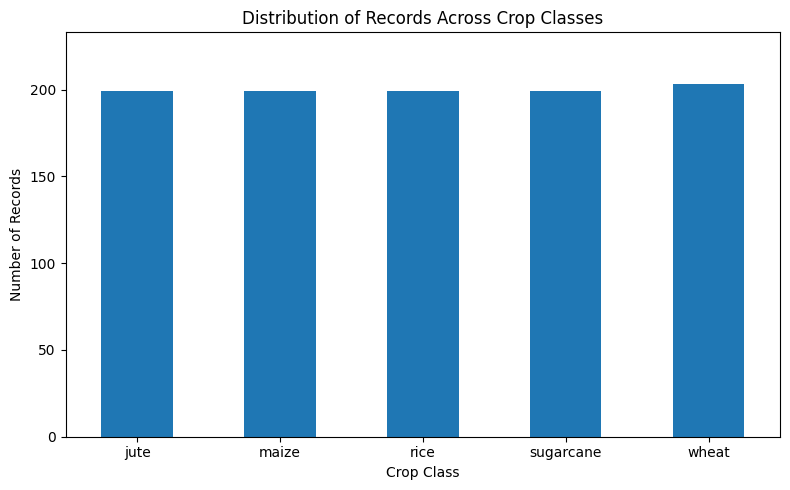

In [21]:
plt.figure(figsize=(8,5))
class_counts.plot(kind="bar")
plt.title("Distribution of Records Across Crop Classes")
plt.xlabel("Crop Class")
plt.ylabel("Number of Records")
plt.ylim(0, max(class_counts.values) + 30)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Sample image inspection

Total image files found: 1106


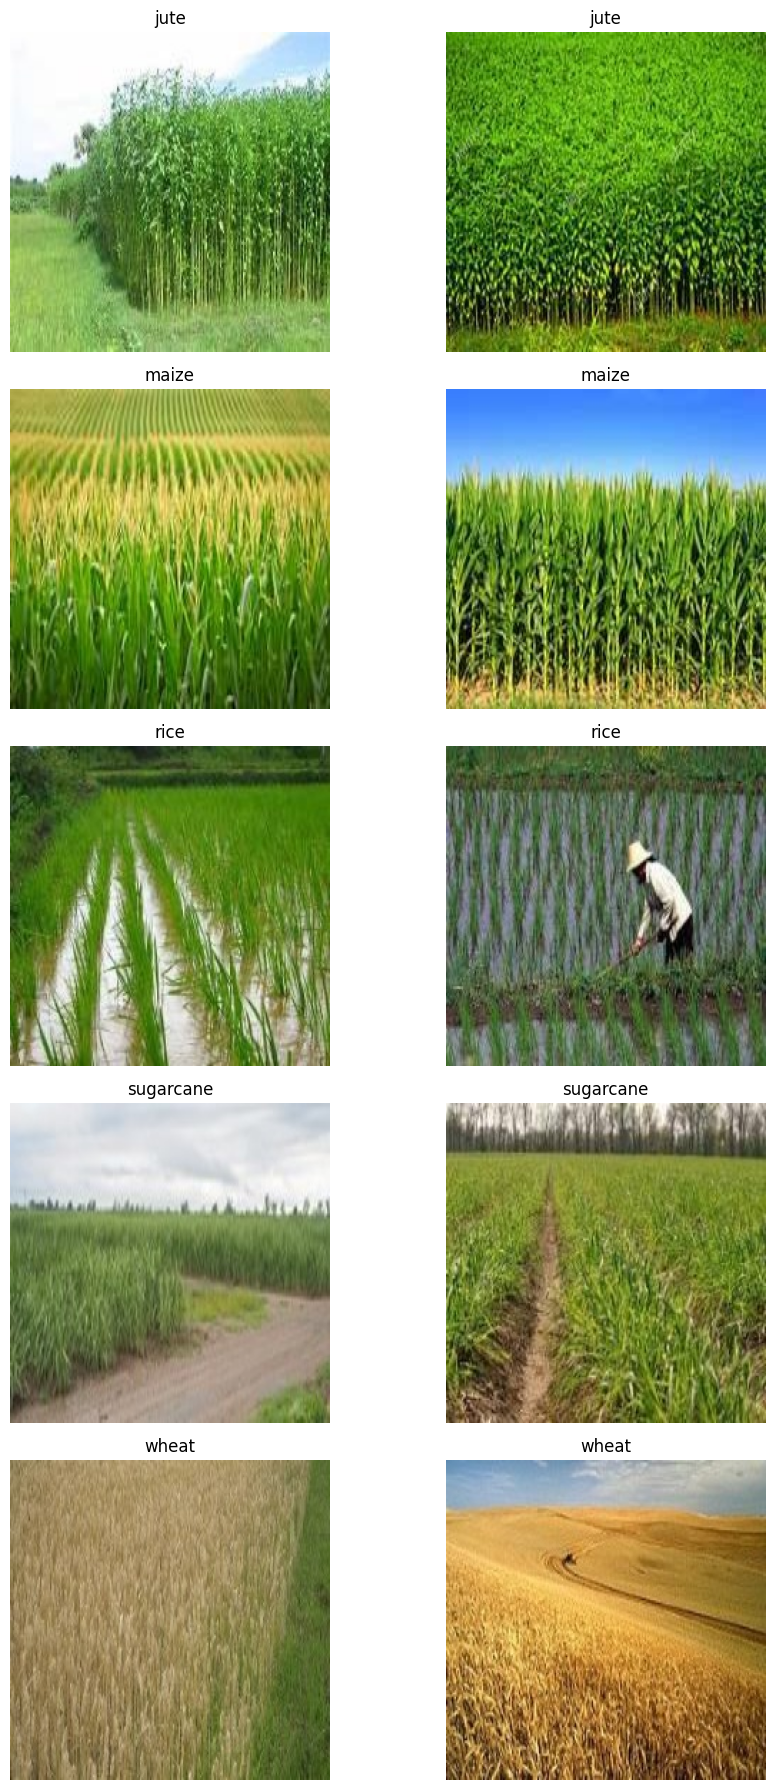

In [22]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".jfif")):
            image_files.append(os.path.join(root, file))

print("Total image files found:", len(image_files))

selected = []
for crop in sorted(df["crop"].unique()):
    candidates = [p for p in image_files if f"/{crop}/" in p.lower().replace("\\", "/")]
    selected.extend(candidates[:2])

fig, axes = plt.subplots(len(selected)//2, 2, figsize=(10, 18))
axes = axes.flatten()

for ax, file_path in zip(axes, selected):
    img = Image.open(file_path).convert("RGB")
    crop_name = file_path.replace("\\", "/").split("/")[-2]
    ax.imshow(img)
    ax.set_title(crop_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

Pivot-style metadata verification

In [23]:
class_counts = df["crop"].value_counts().sort_index()
display(class_counts.rename("count").to_frame())
print("Grand total:", class_counts.sum())

verification_df = class_counts.rename_axis("crop").reset_index(name="count")
verification_df.loc[len(verification_df)] = ["Grand Total", verification_df["count"].sum()]
display(verification_df)

,count
crop,
jute,199
maize,199
rice,199
sugarcane,199
wheat,203


Grand total: 999


,crop,count
0,jute,199
1,maize,199
2,rice,199
3,sugarcane,199
4,wheat,203
5,Grand Total,999


In [24]:
print("Verification Notes")
print("- Total labeled records:", len(df))
print("- Number of classes:", df['crop'].nunique())
print("- Distribution is nearly balanced across all crop categories")
print("- Suitable for supervised classification")
print("- Metadata should still be validated against actual image paths before deployment")

Verification Notes
- Total labeled records: 999
- Number of classes: 5
- Distribution is nearly balanced across all crop categories
- Suitable for supervised classification
- Metadata should still be validated against actual image paths before deployment


Optional veracity check – do metadata paths align with stored files?

In [25]:
import os

all_image_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".jfif")):
            all_image_files.append(os.path.join(root, file))

image_basenames = {os.path.basename(x).lower(): x for x in all_image_files}

if "path" in df.columns:
    df["filename"] = df["path"].apply(lambda x: os.path.basename(str(x)).lower())
    df["filename_found_in_input"] = df["filename"].isin(image_basenames.keys())

    print("Filename-level matches found:", df["filename_found_in_input"].sum())
    print("Filename-level matches NOT found:", (~df["filename_found_in_input"]).sum())
else:
    print("No 'path' column found in the metadata.")

Filename-level matches found: 999
Filename-level matches NOT found: 0


Final findings

In [26]:
print("Final Findings")
print("1. The dataset contains", len(df), "metadata records across", df['crop'].nunique(), "crop classes.")
print("2. The label distribution is nearly balanced, which supports fairer classification.")
print("3. The sample images show visible differences across crop categories.")
print("4. The dataset is suitable for supervised image classification.")
print("5. Metadata and file-path validation should be part of preprocessing before deployment.")

Final Findings
1. The dataset contains 999 metadata records across 5 crop classes.
2. The label distribution is nearly balanced, which supports fairer classification.
3. The sample images show visible differences across crop categories.
4. The dataset is suitable for supervised image classification.
5. Metadata and file-path validation should be part of preprocessing before deployment.


## Conclusion

This verification process shows that the agriculture crop image dataset is suitable for supervised classification tasks.  
The metadata contains 999 labeled records across five crop classes and is nearly balanced, reducing the risk of class imbalance.  
Visual inspection of the images also confirms that the crop categories are distinguishable enough for image-based analysis.  
Overall, the dataset supports the design of a cloud-based crop identification workflow, although metadata and file-path validation remain important preprocessing steps before production use.